## Task 1: Data Loading, EDA & Preprocessing

1.1 Load the Dataset

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target
print('X shape:', X.shape)
print('\nTarget value counts:')
print(y.value_counts())

print('\nX description:')
print(X.describe())

X shape: (569, 30)

Target value counts:
target
1    357
0    212
Name: count, dtype: int64

X description:
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720       

1.2 Class Distribution Plot

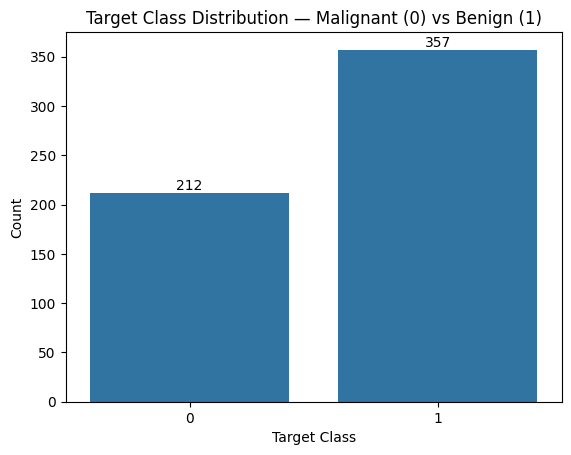

In [2]:
ax = sns.countplot(x=y)

plt.title("Target Class Distribution — Malignant (0) vs Benign (1)")
plt.xlabel("Target Class")
plt.ylabel("Count")
for container in ax.containers:
    ax.bar_label(container)

plt.show()

1.3 Feature Correlation Heatmap

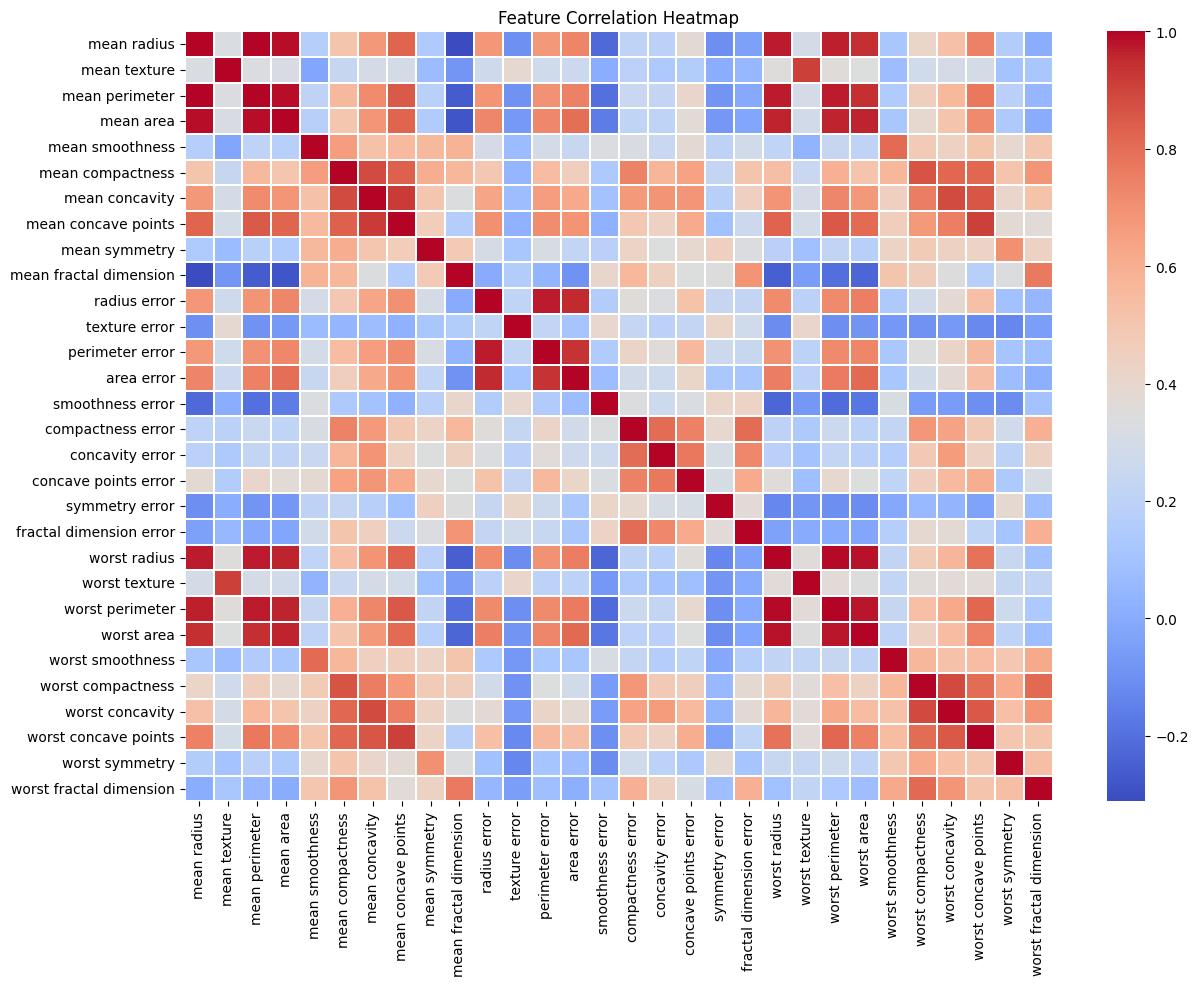

In [3]:
corr_matrix = X.corr()
plt.figure(figsize=(14, 10))

sns.heatmap(corr_matrix,annot=False,cmap="coolwarm",linewidths=0.3)
plt.title("Feature Correlation Heatmap")
plt.show()

1.4 Train / Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('y_train shape:', y_train.shape)
print('y_test shape:', y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)

Training class distribution:
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64

Testing class distribution:
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


1.5 Apply StandardScaler

In [5]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

X_train_sc = pd.DataFrame(X_train_sc,columns=X_train.columns,index=X_train.index)
X_test_sc = pd.DataFrame(X_test_sc,columns=X_test.columns,index=X_test.index)

print("Mean of scaled training features:")
print(X_train_sc.mean(axis=0).round(2))

print("\nStandard deviation of scaled training features:")
print(X_train_sc.std(axis=0).round(2))

Mean of scaled training features:
mean radius               -0.0
mean texture               0.0
mean perimeter            -0.0
mean area                 -0.0
mean smoothness            0.0
mean compactness          -0.0
mean concavity            -0.0
mean concave points        0.0
mean symmetry             -0.0
mean fractal dimension     0.0
radius error              -0.0
texture error             -0.0
perimeter error            0.0
area error                 0.0
smoothness error          -0.0
compactness error         -0.0
concavity error            0.0
concave points error      -0.0
symmetry error             0.0
fractal dimension error    0.0
worst radius               0.0
worst texture             -0.0
worst perimeter           -0.0
worst area                 0.0
worst smoothness           0.0
worst compactness         -0.0
worst concavity            0.0
worst concave points      -0.0
worst symmetry            -0.0
worst fractal dimension    0.0
dtype: float64

Standard deviation o

### Why is the scaler fitted only on X_train?

The StandardScaler must be fitted only on the training data.

When we call:

    scaler.fit(X_train)

the scaler learns the mean and standard deviation from the training
dataset.

Then the same transformation is applied to both datasets:

    X_train_sc = scaler.transform(X_train)
    X_test_sc = scaler.transform(X_test)

We must NOT fit the scaler on X_test because that would allow
information from the test dataset to influence the preprocessing
process. This is called data leakage.

The test set should represent completely unseen data. Therefore,
the test data must only be transformed using the parameters learned
from the training data.


### 1.6 Why Scaling is Important for Neural Networks

Feature scaling is especially important for neural networks because
gradient-based optimizers such as SGD and Adam generally converge
faster and more stably when input features are on a similar scale.

Without scaling, features can have very different numerical ranges.

For example:

- area_mean can have values up to approximately 2500
- fractal_dimension_mean can have values approximately between 0.05
  and 0.10

Because of this large difference in scale, features with large
numerical values can dominate the early gradient updates, while
small-range features may contribute very little.

This can result in:

- Slow convergence
- Unstable optimization
- Biased learning
- Difficulty finding an optimal solution

StandardScaler removes this disparity by transforming the features
so that they have approximately mean = 0 and standard deviation = 1.

Therefore, scaling helps neural networks learn more efficiently and
allows gradient-based optimizers such as SGD and Adam to converge faster and more reliably.

### Task 2: Single-Layer Perceptron (SLP) — Baseline Model

2.1 Build the SLP

In [6]:
import tensorflow as tf
from tensorflow import keras

model_slp = keras.Sequential([
    keras.layers.Dense(
        1,
        activation='sigmoid',
        input_shape=(30,)
    )
])

model_slp.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

2.2 Compile the SLP

In [7]:
model_slp.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

model_slp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

### Why Binary Crossentropy?

Binary crossentropy is the appropriate loss function for binary
classification problems.

The SLP uses a sigmoid activation function, which produces an output
probability between 0 and 1.

Binary crossentropy measures the difference between the predicted
probability and the actual binary class label.

Mean Squared Error (MSE) is mainly designed for regression problems.
Although MSE can technically be used with a sigmoid classifier,
binary crossentropy generally provides better gradients and is more
appropriate for binary classification.

Therefore, binary crossentropy is used as the loss function for the SLP.

2.3 Train the SLP

In [8]:
history_slp = model_slp.fit(X_train_sc,y_train,epochs=50,batch_size=32,validation_split=0.1,verbose=1)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.3863 - loss: 1.0204 - val_accuracy: 0.3478 - val_loss: 1.1150
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.4450 - loss: 0.9216 - val_accuracy: 0.3696 - val_loss: 1.0184
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4988 - loss: 0.8342 - val_accuracy: 0.4348 - val_loss: 0.9320
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5623 - loss: 0.7565 - val_accuracy: 0.4783 - val_loss: 0.8556
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6112 - loss: 0.6894 - val_accuracy: 0.5217 - val_loss: 0.7887
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6553 - loss: 0.6324 - val_accuracy: 0.6304 - val_loss: 0.7302
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7042 - loss: 0.5829 - val_accuracy: 0.6739 - val_loss: 0.6790
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7359 - loss: 0.5397 - val_accuracy: 0.7391 - val_l

2.4 Plot SLP Training Curves

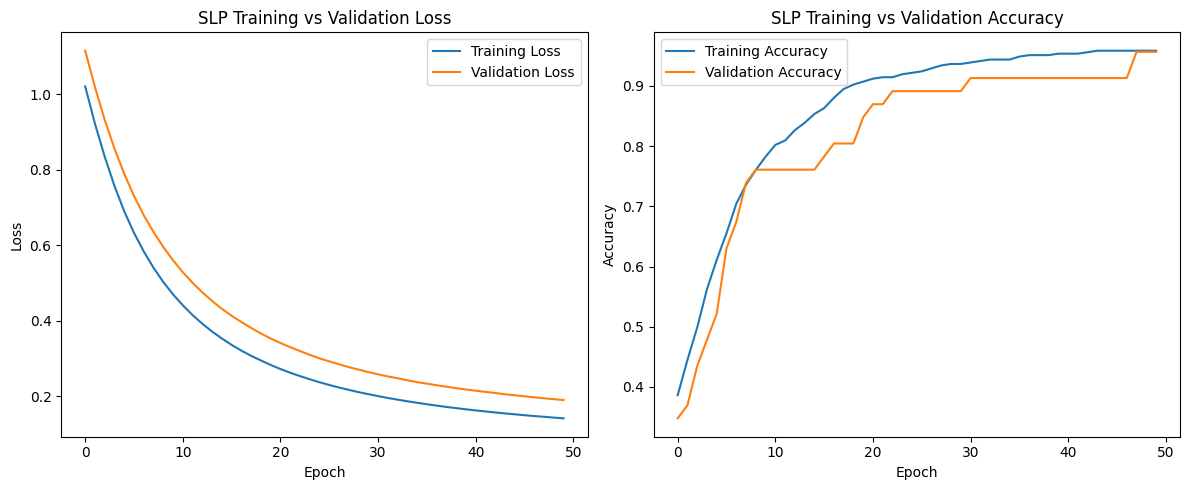

In [9]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

plt.plot(
    history_slp.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_slp.history['val_loss'],
    label='Validation Loss'
)

plt.title('SLP Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history_slp.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_slp.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('SLP Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

### describe what the curves reveal

The training loss generally decreases as the number of epochs
increases, while training accuracy increases.

The validation loss and validation accuracy should follow a similar
trend.

If training accuracy becomes much higher than validation accuracy,
and validation loss starts increasing, it indicates overfitting.

For this dataset, the SLP generally performs well because the breast
cancer features provide strong information for separating the two
classes.

A small difference between training and validation performance
indicates that the SLP is learning reasonably well without severe
overfitting.

2.5 Evaluate the SLP

SLP Test Accuracy: 0.9561403393745422
SLP Test Loss: 0.16500119864940643

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.90      0.94        42
           1       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



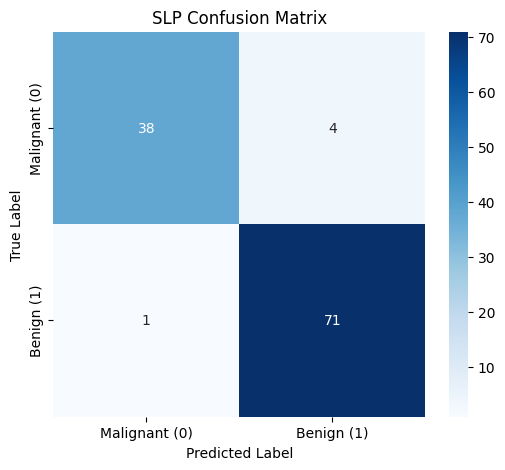

In [10]:
from sklearn.metrics import classification_report, confusion_matrix

slp_loss, slp_acc = model_slp.evaluate(X_test_sc,y_test,verbose=0)

print("SLP Test Accuracy:", slp_acc)
print("SLP Test Loss:", slp_loss)

y_pred_slp = (
    model_slp.predict(X_test_sc, verbose=0) > 0.5
).astype(int).ravel()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_slp))

cm = confusion_matrix(y_test, y_pred_slp)

plt.figure(figsize=(6, 5))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Malignant (0)', 'Benign (1)'],yticklabels=['Malignant (0)', 'Benign (1)'])

plt.title("SLP Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

2.6 SLP Limitations — Markdown

A Single-Layer Perceptron (SLP) can learn only linearly separable
decision boundaries.

In this problem, the SLP creates a single hyperplane in the
30-dimensional feature space.

Therefore, the SLP cannot effectively learn complex nonlinear
relationships between features.

Although the breast cancer dataset is classified quite well by the
SLP because many of its features provide strong linear separation,
the problem is not guaranteed to be perfectly linearly separable.

This makes the SLP a useful baseline model, but it has limited
capacity for learning complex patterns.

An MLP (Multi-Layer Perceptron) introduces one or more hidden layers
and nonlinear activation functions. This allows it to learn more
complex nonlinear decision boundaries.

Therefore, the SLP provides a baseline for comparison with the more
powerful MLP model in Task 3.

### Task 3: Multi-Layer Perceptron (MLP) — Activation Functions

3.1 Build the MLP (ReLU)

In [11]:
model_mlp = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(30,)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_mlp.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

3.2 WHY Hidden Layers — Markdown

Each Dense layer learns a transformation of its inputs and introduces
non-linearity through its activation function.

The first hidden layer contains 64 neurons and learns different
combinations of the original 30 input features.

The second hidden layer contains 32 neurons and combines the features
learned by the first hidden layer.

Therefore, stacking hidden layers allows the neural network to learn
multiple levels of feature interactions.

A single hidden layer can theoretically approximate any continuous
function under suitable conditions, as described by the Universal
Approximation Theorem. However, deeper networks can often represent
complex functions more efficiently and may converge faster in practice.

More layers can therefore create a feature hierarchy:

Input features → Low-level feature combinations → Higher-level
feature representations → Final classification

3.3 Compile and Train MLP (ReLU)

In [12]:
model_mlp.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
history_mlp = model_mlp.fit(X_train_sc,y_train,epochs=100,batch_size=32,validation_split=0.1,verbose=1)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8509 - loss: 0.4795 - val_accuracy: 0.8913 - val_loss: 0.3730
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9389 - loss: 0.2558 - val_accuracy: 0.9130 - val_loss: 0.2453
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9560 - loss: 0.1619 - val_accuracy: 0.9130 - val_loss: 0.1944
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9658 - loss: 0.1201 - val_accuracy: 0.9348 - val_loss: 0.1618
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9707 - loss: 0.0976 - val_accuracy: 0.9565 - val_loss: 0.1354
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.0841 - val_accuracy: 0.9565 - val_loss: 0.1156
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0750 - val_accuracy: 0.9565 - val_loss: 0.1012
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0684 - val_accuracy: 0.9565 - 

3.4 Compare Activation Functions

In [13]:
#(a) MLP with ReLU

model_relu = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(30,)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_relu.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_relu = model_relu.fit(
    X_train_sc,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=0
)


#(b) MLP with Tanh

model_tanh = keras.Sequential([
    keras.layers.Dense(64, activation='tanh', input_shape=(30,)),
    keras.layers.Dense(32, activation='tanh'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_tanh.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_tanh = model_tanh.fit(
    X_train_sc,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=0
)


#(c) MLP with Sigmoid in hidden layers

model_sigmoid = keras.Sequential([
    keras.layers.Dense(64, activation='sigmoid', input_shape=(30,)),
    keras.layers.Dense(32, activation='sigmoid'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_sigmoid.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_sigmoid = model_sigmoid.fit(
    X_train_sc,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=0
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


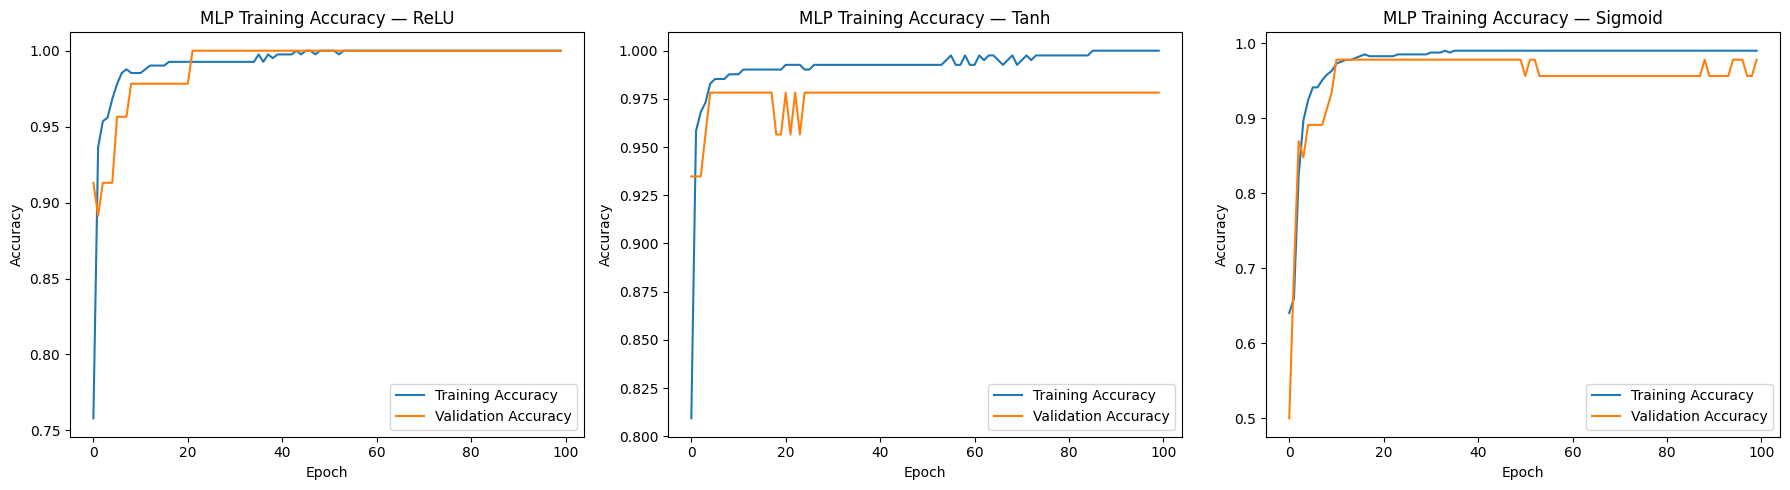

In [14]:
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1)

plt.plot(history_relu.history['accuracy'],label='Training Accuracy')
plt.plot(history_relu.history['val_accuracy'],label='Validation Accuracy')

plt.title('MLP Training Accuracy — ReLU')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 3, 2)

plt.plot(history_tanh.history['accuracy'],label='Training Accuracy')
plt.plot(history_tanh.history['val_accuracy'],label='Validation Accuracy')

plt.title('MLP Training Accuracy — Tanh')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 3, 3)

plt.plot(history_sigmoid.history['accuracy'],label='Training Accuracy')
plt.plot(history_sigmoid.history['val_accuracy'],label='Validation Accuracy')

plt.title('MLP Training Accuracy — Sigmoid')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

3.5 Activation Functions — Markdown

### Comparison of Activation Functions

#### 1. ReLU

ReLU (Rectified Linear Unit) is defined as:

f(x) = max(0, x)

For negative inputs, ReLU outputs 0. For positive inputs, it outputs
the input value.

Advantages:
- Computationally simple and fast
- Helps reduce the vanishing-gradient problem compared with sigmoid
- Allows faster convergence
- Produces sparse activations because negative values become zero

Disadvantage:
- Can suffer from the "dying ReLU" problem when neurons remain inactive
  for negative inputs.

ReLU is commonly used in hidden layers of modern neural networks.


#### 2. Tanh

The tanh activation function produces values between -1 and +1.

Advantages:
- Zero-centered output
- Generally better than sigmoid for hidden layers
  because its outputs are centered around zero

Disadvantage:
- Can suffer from vanishing gradients when the input magnitude
  becomes large.

Tanh can work well for smaller neural networks and normalized data.


#### 3. Sigmoid

The sigmoid function produces values between 0 and 1.

Advantages:
- Produces probability-like outputs
- Useful for binary classification output layers

Disadvantages:
- Not zero-centered
- Can suffer from severe vanishing-gradient problems in deep networks
- Often results in slower training compared with ReLU

Therefore, sigmoid is generally preferred for the output layer of a
binary classification network rather than for multiple hidden layers.


### Best Activation Function

For this breast cancer dataset, ReLU will generally perform best or
among the best because it provides faster gradient-based optimization
and avoids much of the vanishing-gradient problem associated with
sigmoid.

Tanh can also perform well because the features have already been
standardized using StandardScaler.

Sigmoid in the hidden layers generally converges more slowly because
its gradients become very small when activations saturate.

Therefore, the recommended configuration is:

Hidden layers → ReLU
Output layer → Sigmoid

3.6 Evaluate Best MLP

In [15]:
relu_loss, relu_acc = model_relu.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

tanh_loss, tanh_acc = model_tanh.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

sigmoid_loss, sigmoid_acc = model_sigmoid.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

print("ReLU Test Accuracy:", relu_acc)
print("Tanh Test Accuracy:", tanh_acc)
print("Sigmoid Test Accuracy:", sigmoid_acc)

ReLU Test Accuracy: 0.9561403393745422
Tanh Test Accuracy: 0.9649122953414917
Sigmoid Test Accuracy: 0.9561403393745422


### Task 4: Early Stopping

4.1 Build MLP for Early Stopping Experiment

In [16]:
model_es = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_es.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_es.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

4.2 Add EarlyStopping Callback

In [17]:
es = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history_es = model_es.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es],
    verbose=1
)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7922 - loss: 0.4683 - val_accuracy: 0.9565 - val_loss: 0.2643
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9658 - loss: 0.1680 - val_accuracy: 0.9783 - val_loss: 0.1622
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9756 - loss: 0.1025 - val_accuracy: 0.9783 - val_loss: 0.1230
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9756 - loss: 0.0804 - val_accuracy: 0.9783 - val_loss: 0.0928
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9780 - loss: 0.0673 - val_accuracy: 0.9783 - val_loss: 0.0732
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9829 - loss: 0.0587 - val_accuracy: 0.9783 - val_loss: 0.0636
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9902 - loss: 0.0525 - val_accuracy: 0.9783 - val_loss: 0.0600
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9902 - loss: 0.0481 - val_accuracy: 0.9783 - 

4.3 WHY Early Stopping — Markdown

Early Stopping is a regularization technique used to prevent
overfitting during neural-network training.

The following four parameters are used:

#### 1. monitor='val_loss'

The callback monitors the validation loss instead of training loss.

Training loss generally continues to decrease as the model learns the
training data. Therefore, it is not a reliable indicator of
generalization.

Validation loss provides information about how well the model performs
on unseen validation data.

When validation loss starts increasing, it can indicate overfitting.

#### 2. patience=15

The model waits for 15 consecutive epochs without improvement in
validation loss before stopping training.

This prevents the model from stopping immediately because of a
temporary plateau or small fluctuation in validation loss.

#### 3. restore_best_weights=True

After training stops, the model weights are restored to the epoch
where the lowest validation loss was achieved.

Without this parameter, the model would keep the weights from the
final epoch, which may already be overfitted.

Therefore, the final model uses the best-performing weights rather
than the weights from the last epoch.

#### 4. verbose=1

This displays information about the training process and prints the
epoch at which Early Stopping occurs.

Therefore, Early Stopping helps the model stop training at an
appropriate point and improves generalization while reducing
unnecessary training time.

4.4 Plot Early Stopping Curves

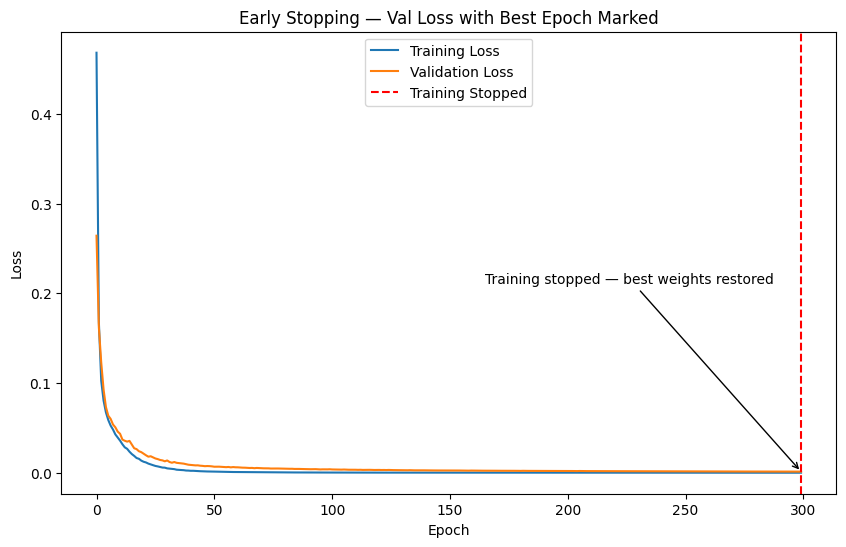

In [18]:
plt.figure(figsize=(10, 6))

plt.plot(history_es.history['loss'],label='Training Loss')
plt.plot(history_es.history['val_loss'],label='Validation Loss')

stopped_epoch = len(history_es.history['loss'])
plt.axvline(
    x=stopped_epoch - 1,
    color='red',
    linestyle='--',
    label='Training Stopped'
)

plt.annotate(
    'Training stopped — best weights restored',
    xy=(stopped_epoch - 1, history_es.history['val_loss'][-1]),
    xytext=(stopped_epoch * 0.55, max(history_es.history['val_loss']) * 0.8),
    arrowprops=dict(arrowstyle='->')
)

plt.title('Early Stopping — Val Loss with Best Epoch Marked')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

4.5 Compare: With vs Without Early Stopping

In [19]:
model_no_es = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

model_no_es.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_no_es = model_no_es.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    verbose=0
)

print("Training completed for 300 epochs.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training completed for 300 epochs.


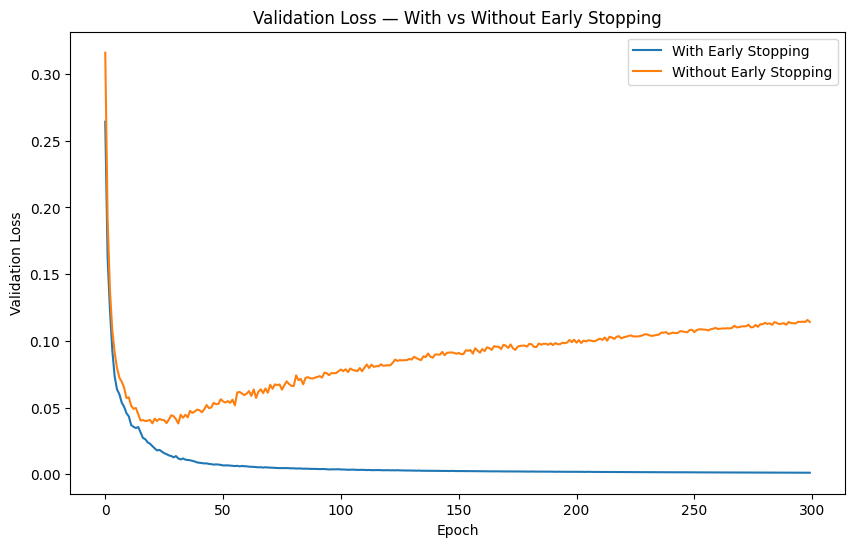

In [20]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_es.history['val_loss'],
    label='With Early Stopping'
)

plt.plot(
    history_no_es.history['val_loss'],
    label='Without Early Stopping'
)

plt.title('Validation Loss — With vs Without Early Stopping')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()

plt.show()

### Task 5: Dropout Layers

5.1 Build MLP with Dropout

In [21]:
model_drop = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation='sigmoid')
])

model_drop.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

5.2 WHY Dropout — Markdown

Dropout is a regularization technique used to reduce overfitting in
neural networks.

In this model, Dropout(rate=0.3) randomly sets 30% of neuron
activations to zero during each training batch.

This prevents the network from depending too heavily on particular
neurons and forces it to learn more robust and distributed
representations.

No single neuron can be relied upon because different neurons are
randomly disabled during training.

During inference, such as when using model.predict(), dropout is
automatically disabled and all neurons contribute to the prediction.
The activations are appropriately scaled according to the keep
probability.

Dropout can be viewed as approximately training an ensemble of many
different thinned neural networks and averaging their predictions.

Therefore, Dropout can reduce variance, reduce overfitting, and
improve generalisation to unseen data.

5.3 Train with Dropout + Early Stopping

In [22]:
model_drop.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

es_drop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history_drop = model_drop.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_drop],
    verbose=1
)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5575 - loss: 0.6927 - val_accuracy: 0.9130 - val_loss: 0.4042
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9364 - loss: 0.3158 - val_accuracy: 0.9130 - val_loss: 0.2473
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9609 - loss: 0.1861 - val_accuracy: 0.9130 - val_loss: 0.1904
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9584 - loss: 0.1340 - val_accuracy: 0.9348 - val_loss: 0.1566
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9682 - loss: 0.1088 - val_accuracy: 0.9348 - val_loss: 0.1363
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9707 - loss: 0.0894 - val_accuracy: 0.9565 - val_loss: 0.1192
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9756 - loss: 0.0866 - val_accuracy: 0.9565 - val_loss: 0.1113
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9731 - loss: 0.0774 - val_accuracy: 0.9565 - 

5.4 Effect of Dropout Rate

In [23]:
# Dropout rate = 0.1

model_drop_01 = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.1),
    keras.layers.Dense(1, activation='sigmoid')
])

model_drop_01.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

es_01 = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=0
)

history_drop_01 = model_drop_01.fit(
    X_train_sc,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_01],
    verbose=0
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
# Dropout rate = 0.5

model_drop_05 = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(1, activation='sigmoid')
])

model_drop_05.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

es_05 = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=0
)

history_drop_05 = model_drop_05.fit(
    X_train_sc,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_05],
    verbose=0
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


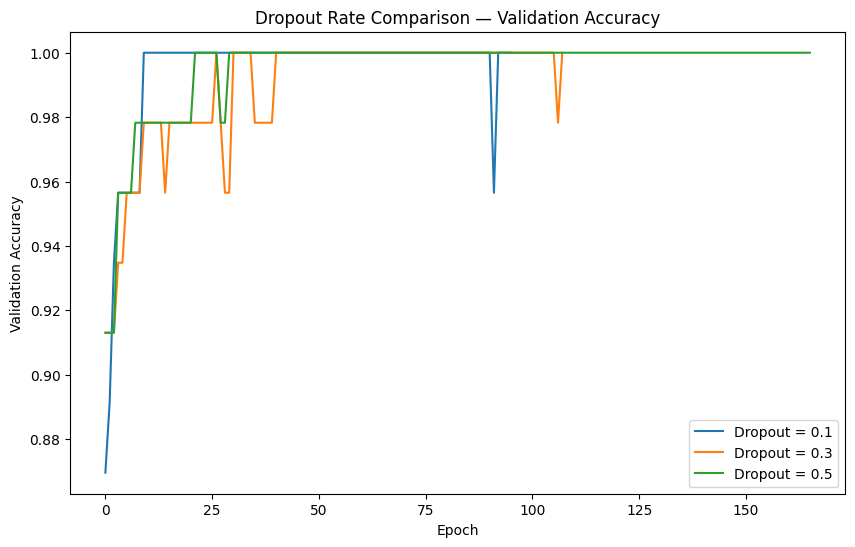

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_drop_01.history['val_accuracy'],
    label='Dropout = 0.1'
)

plt.plot(
    history_drop.history['val_accuracy'],
    label='Dropout = 0.3'
)

plt.plot(
    history_drop_05.history['val_accuracy'],
    label='Dropout = 0.5'
)

plt.title('Dropout Rate Comparison — Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()

plt.show()

5.5 Evaluate Dropout Model

In [26]:
drop_loss, drop_acc = model_drop.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

print("Dropout Model Test Loss:", drop_loss)
print("Dropout Model Test Accuracy:", drop_acc)

Dropout Model Test Loss: 0.15968537330627441
Dropout Model Test Accuracy: 0.9561403393745422


In [27]:
y_pred_drop = (
    model_drop.predict(X_test_sc, verbose=0) > 0.5
).astype(int).ravel()

print("Classification Report — Dropout MLP")
print(
    classification_report(
        y_test,
        y_pred_drop
    )
)

Classification Report — Dropout MLP
              precision    recall  f1-score   support

           0       0.91      0.98      0.94        42
           1       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



In [28]:
drop_train_acc = history_drop.history['accuracy'][-1]
drop_val_acc = history_drop.history['val_accuracy'][-1]

no_drop_train_acc = history_es.history['accuracy'][-1]
no_drop_val_acc = history_es.history['val_accuracy'][-1]

print("WITHOUT DROPOUT")
print("Training Accuracy:", no_drop_train_acc)
print("Validation Accuracy:", no_drop_val_acc)
print(
    "Accuracy Gap:",
    abs(no_drop_train_acc - no_drop_val_acc)
)

print("\nWITH DROPOUT")
print("Training Accuracy:", drop_train_acc)
print("Validation Accuracy:", drop_val_acc)
print(
    "Accuracy Gap:",
    abs(drop_train_acc - drop_val_acc)
)

WITHOUT DROPOUT
Training Accuracy: 1.0
Validation Accuracy: 1.0
Accuracy Gap: 0.0

WITH DROPOUT
Training Accuracy: 0.9975550174713135
Validation Accuracy: 1.0
Accuracy Gap: 0.0024449825286865234


###Task 6: Regularization (L1, L2, L1-L2)

6.1 Build MLP with L2 Regularization

In [29]:
model_l2 = keras.Sequential([
    keras.layers.Dense(
        128,
        activation='relu',
        input_shape=(30,),
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dense(
        64,
        activation='relu',
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dense(
        1,
        activation='sigmoid'
    )
])

model_l2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_l2 = model_l2.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=20,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)

Epoch 1/300


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7873 - loss: 0.6348 - val_accuracy: 0.9130 - val_loss: 0.4602
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9584 - loss: 0.3454 - val_accuracy: 0.9130 - val_loss: 0.3451
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9707 - loss: 0.2560 - val_accuracy: 0.9565 - val_loss: 0.2775
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.2179 - val_accuracy: 0.9783 - val_loss: 0.2397
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9829 - loss: 0.1982 - val_accuracy: 0.9783 - val_loss: 0.2194
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9829 - loss: 0.1847 - val_accuracy: 0.9783 - val_loss: 0.2019
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9878 - loss: 0.1755 - val_accuracy: 0.9783 - val_loss: 0.1892
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9902 - loss: 0.1671 - val_accuracy: 0.9783 - val_loss: 0.

6.2 WHY L2 Regularization — Markdown

-L2 regularization adds a penalty term to the loss function.

The L2 penalty is:

λ × Σw²

where:

- λ is the regularization strength
- w represents the model weights

Therefore, the total loss becomes:

Total Loss = Binary Crossentropy + λ × Σw²

L2 regularization penalizes large weight values. It encourages the
network to distribute its learning across many smaller weights rather
than relying heavily on a few very large weights.

This generally produces a smoother decision boundary and can reduce
variance and overfitting.

For this task:

λ = 0.001

A moderate value such as 0.001 provides regularisation without
excessively restricting the model.

If λ is too large, the weights are penalised too strongly and the
model may underfit because it cannot learn sufficiently complex
patterns.

6.3 Build MLP with L1 Regularization

In [30]:
# 6.3 Build MLP with L1 Regularization

model_l1 = keras.Sequential([
    keras.layers.Dense(
        128,
        activation='relu',
        input_shape=(30,),
        kernel_regularizer=keras.regularizers.l1(0.001)
    ),
    keras.layers.Dense(
        64,
        activation='relu',
        kernel_regularizer=keras.regularizers.l1(0.001)
    ),
    keras.layers.Dense(
        1,
        activation='sigmoid'
    )
])

model_l1.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_l1 = model_l1.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=20,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)

Epoch 1/300


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.8460 - loss: 1.5185 - val_accuracy: 0.9348 - val_loss: 1.3262
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9511 - loss: 1.2096 - val_accuracy: 0.9565 - val_loss: 1.1889
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9658 - loss: 1.1060 - val_accuracy: 0.9565 - val_loss: 1.0974
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9780 - loss: 1.0359 - val_accuracy: 0.9783 - val_loss: 1.0159
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9804 - loss: 0.9710 - val_accuracy: 0.9783 - val_loss: 0.9568
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9829 - loss: 0.9117 - val_accuracy: 0.9783 - val_loss: 0.8968
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9853 - loss: 0.8554 - val_accuracy: 0.9783 - val_loss: 0.8354
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9878 - loss: 0.8011 - val_accuracy: 0.9783 - val_l

### Why L1 Regularization?

L1 regularization adds the following penalty to the loss:

λ × Σ|w|

Unlike L2, which penalizes the squared magnitude of weights, L1
penalizes the absolute magnitude of weights.

A major property of L1 regularization is that it can drive some
weights exactly to zero.

Therefore, L1 can produce a sparse model where some features have
little or no influence on the prediction.

This behaviour is similar to performing feature selection because
features associated with zero-valued weights effectively contribute
little to the model.

For a dataset with 30 features, such as the Breast Cancer dataset,
L1 regularization may remove weakly predictive or redundant feature
connections.

Therefore:

L1 → sparse weights → possible feature selection

6.4 Build MLP with L1-L2 (ElasticNet)

In [31]:
model_l1l2 = keras.Sequential([
    keras.layers.Dense(
        128,
        activation='relu',
        input_shape=(30,),
        kernel_regularizer=keras.regularizers.l1_l2(
            l1=0.001,
            l2=0.001
        )
    ),
    keras.layers.Dense(
        64,
        activation='relu',
        kernel_regularizer=keras.regularizers.l1_l2(
            l1=0.001,
            l2=0.001
        )
    ),
    keras.layers.Dense(
        1,
        activation='sigmoid'
    )
])

model_l1l2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_l1l2 = model_l1l2.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=20,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)

Epoch 1/300


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8680 - loss: 1.6674 - val_accuracy: 0.9130 - val_loss: 1.4881
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9560 - loss: 1.3510 - val_accuracy: 0.9783 - val_loss: 1.3182
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9633 - loss: 1.2259 - val_accuracy: 0.9565 - val_loss: 1.2181
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9780 - loss: 1.1324 - val_accuracy: 0.9565 - val_loss: 1.1196
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9804 - loss: 1.0501 - val_accuracy: 0.9783 - val_loss: 1.0280
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9804 - loss: 0.9720 - val_accuracy: 0.9783 - val_loss: 0.9458
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9829 - loss: 0.8981 - val_accuracy: 0.9783 - val_loss: 0.8747
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9902 - loss: 0.8278 - val_accuracy: 0.9783 - val_loss: 0.

6.5 Regularization Comparison Plot

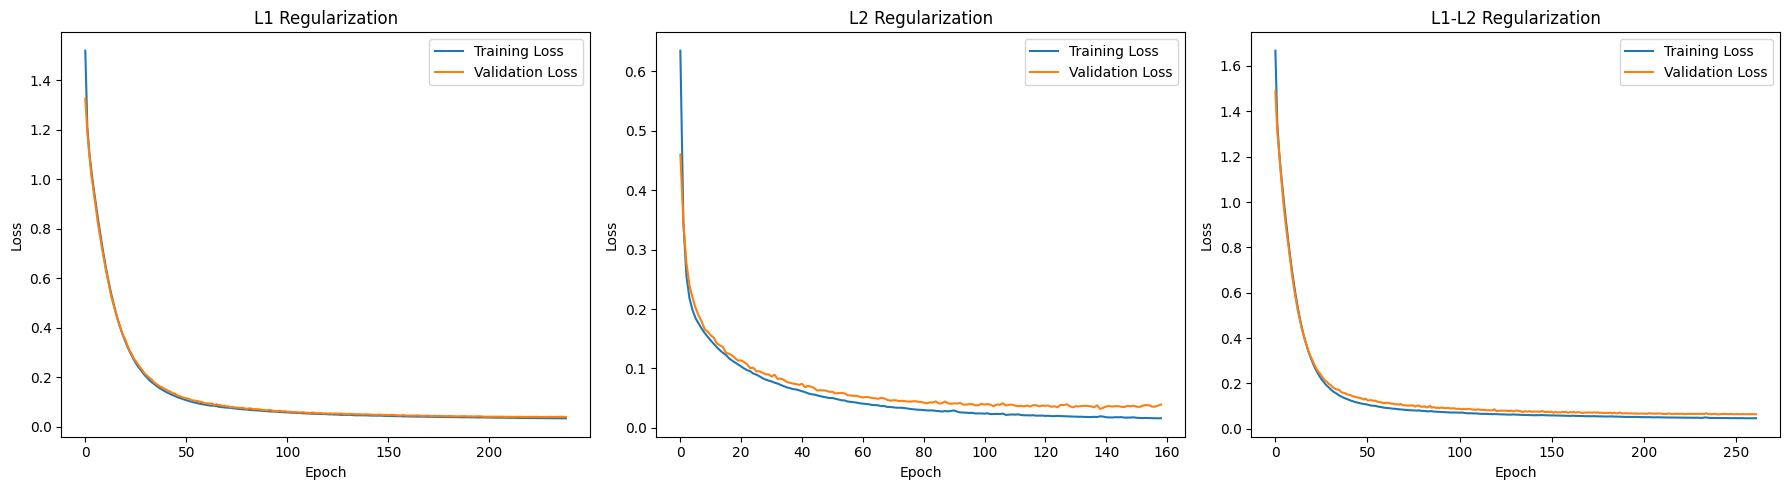

In [32]:
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1)

plt.plot(
    history_l1.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_l1.history['val_loss'],
    label='Validation Loss'
)

plt.title('L1 Regularization')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)

plt.plot(
    history_l2.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_l2.history['val_loss'],
    label='Validation Loss'
)

plt.title('L2 Regularization')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 3)

plt.plot(
    history_l1l2.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_l1l2.history['val_loss'],
    label='Validation Loss'
)

plt.title('L1-L2 Regularization')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

6.6 Evaluate All Three Regularized Models

In [33]:
l1_loss, l1_acc = model_l1.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

l2_loss, l2_acc = model_l2.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

l1l2_loss, l1l2_acc = model_l1l2.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

print("L1 Test Loss:", l1_loss)
print("L1 Test Accuracy:", l1_acc)

print("\nL2 Test Loss:", l2_loss)
print("L2 Test Accuracy:", l2_acc)

print("\nL1-L2 Test Loss:", l1l2_loss)
print("L1-L2 Test Accuracy:", l1l2_acc)

L1 Test Loss: 0.18096430599689484
L1 Test Accuracy: 0.9561403393745422

L2 Test Loss: 0.14237891137599945
L2 Test Accuracy: 0.9473684430122375

L1-L2 Test Loss: 0.11784520745277405
L1-L2 Test Accuracy: 0.9736841917037964


In [34]:
regularization_results = {
    'L1': l1_acc,
    'L2': l2_acc,
    'L1-L2': l1l2_acc
}

best_regularization = max(
    regularization_results,
    key=regularization_results.get
)

best_regularization_accuracy = regularization_results[
    best_regularization
]

print("Best Regularization:", best_regularization)
print(
    "Best Test Accuracy:",
    best_regularization_accuracy
)

Best Regularization: L1-L2
Best Test Accuracy: 0.9736841917037964


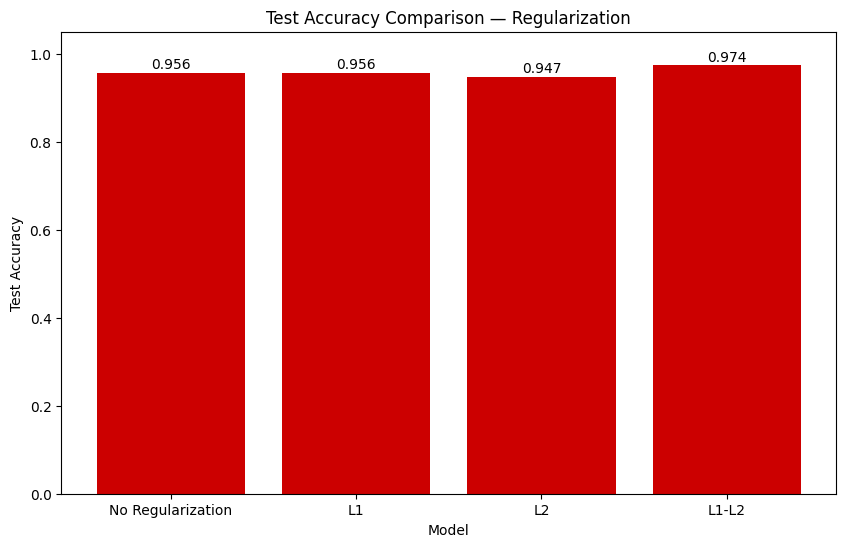

In [35]:
no_reg_loss, no_reg_acc = model_relu.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

model_names = [
    'No Regularization',
    'L1',
    'L2',
    'L1-L2'
]

test_accuracies = [
    no_reg_acc,
    l1_acc,
    l2_acc,
    l1l2_acc
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    model_names,
    test_accuracies,
    color='#CC0000'
)

plt.title('Test Accuracy Comparison — Regularization')
plt.xlabel('Model')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1.05)

for bar, accuracy in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f'{accuracy:.3f}',
        ha='center'
    )

plt.show()

###Task 7: Final Comparison, Business Insights & Notebook Quality

7.1 Best Model: Dropout + L2 + Early Stopping

In [36]:
model_final = keras.Sequential([
    keras.layers.Dense(
        128,
        activation='relu',
        input_shape=(30,),
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(
        64,
        activation='relu',
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(
        1,
        activation='sigmoid'
    )
])

model_final.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

es_final = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history_final = model_final.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_final],
    verbose=1
)

model_final.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.7311 - loss: 0.6748 - val_accuracy: 0.8913 - val_loss: 0.4983
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9364 - loss: 0.4197 - val_accuracy: 0.9130 - val_loss: 0.3714
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9535 - loss: 0.3007 - val_accuracy: 0.9130 - val_loss: 0.3157
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9609 - loss: 0.2553 - val_accuracy: 0.9348 - val_loss: 0.2819
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9658 - loss: 0.2242 - val_accuracy: 0.9565 - val_loss: 0.2533
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9731 - loss: 0.2137 - val_accuracy: 0.9565 - val_loss: 0.2355
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9804 - loss: 0.2038 - val_accuracy: 0.9565 - val_loss: 0.2200
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9829 - loss: 0.1872 - val_accuracy: 0.

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_37 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,869 (144.02 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 24,580 (96.02 KB)

7.2 Full Results Comparison Table

In [37]:
final_loss, final_acc = model_final.evaluate(
    X_test_sc,
    y_test,
    verbose=0
)

y_pred_final = (
    model_final.predict(X_test_sc, verbose=0) > 0.5
).astype(int).ravel()

print("Final Model Test Loss:", final_loss)
print("Final Model Test Accuracy:", final_acc)

print("\nFinal Model Classification Report:")
print(classification_report(y_test, y_pred_final))

Final Model Test Loss: 0.14567285776138306
Final Model Test Accuracy: 0.9561403393745422

Final Model Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.94        42
           1       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



In [38]:
def get_metrics(model):
    y_pred = (
        model.predict(X_test_sc, verbose=0) > 0.5
    ).astype(int).ravel()

    report = classification_report(
        y_test,
        y_pred,
        output_dict=True
    )

    return {
        'Test Accuracy': report['accuracy'],
        'Test Precision': report['weighted avg']['precision'],
        'Test Recall': report['weighted avg']['recall'],
        'Test F1-Score': report['weighted avg']['f1-score']
    }

In [39]:
dropout_models = {
    'Dropout 0.1': model_drop_01,
    'Dropout 0.3': model_drop,
    'Dropout 0.5': model_drop_05
}

dropout_histories = {
    'Dropout 0.1': history_drop_01,
    'Dropout 0.3': history_drop,
    'Dropout 0.5': history_drop_05
}

best_dropout_name = max(
    dropout_histories,
    key=lambda x: max(
        dropout_histories[x].history['val_accuracy']
    )
)

best_dropout_model = dropout_models[best_dropout_name]

print("Best Dropout Model:", best_dropout_name)

Best Dropout Model: Dropout 0.1


In [40]:
results = []
slp_metrics = get_metrics(model_slp)

results.append({
    'Model': 'SLP',
    'Architecture': 'Dense(1, sigmoid)',
    'Regularization': 'None',
    'Dropout Rate': 0,
    'Early Stopping': 'No',
    **slp_metrics
})

relu_metrics = get_metrics(model_relu)

results.append({
    'Model': 'MLP-ReLU',
    'Architecture': '128 → 64 → 1',
    'Regularization': 'None',
    'Dropout Rate': 0,
    'Early Stopping': 'No',
    **relu_metrics
})

es_metrics = get_metrics(model_es)

results.append({
    'Model': 'MLP + Early Stopping',
    'Architecture': '128 → 64 → 1',
    'Regularization': 'None',
    'Dropout Rate': 0,
    'Early Stopping': 'Yes',
    **es_metrics
})

drop_metrics = get_metrics(best_dropout_model)

best_dropout_rate = {
    'Dropout 0.1': 0.1,
    'Dropout 0.3': 0.3,
    'Dropout 0.5': 0.5
}[best_dropout_name]

results.append({
    'Model': 'MLP + Dropout',
    'Architecture': '128 → 64 → 1',
    'Regularization': 'None',
    'Dropout Rate': best_dropout_rate,
    'Early Stopping': 'Yes',
    **drop_metrics
})

l2_metrics = get_metrics(model_l2)

results.append({
    'Model': 'MLP + L2',
    'Architecture': '128 → 64 → 1',
    'Regularization': 'L2 (0.001)',
    'Dropout Rate': 0,
    'Early Stopping': 'Yes',
    **l2_metrics
})

final_metrics = get_metrics(model_final)

results.append({
    'Model': 'Final Combined Model',
    'Architecture': '128 → 64 → 1',
    'Regularization': 'L2 (0.001)',
    'Dropout Rate': 0.3,
    'Early Stopping': 'Yes',
    **final_metrics
})

results_df = pd.DataFrame(results)
results_df

,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP,"Dense(1, sigmoid)",None,0.0,No,0.956140,0.956869,0.956140,0.955776
1,MLP-ReLU,128 → 64 → 1,None,0.0,No,0.956140,0.958098,0.956140,0.956430
2,MLP + Early Stopping,128 → 64 → 1,None,0.0,Yes,0.964912,0.965858,0.964912,0.965073
3,MLP + Dropout,128 → 64 → 1,None,0.1,Yes,0.964912,0.965858,0.964912,0.965073
4,MLP + L2,128 → 64 → 1,L2 (0.001),0.0,Yes,0.947368,0.950666,0.947368,0.947813
5,Final Combined Model,128 → 64 → 1,L2 (0.001),0.3,Yes,0.956140,0.958098,0.956140,0.956430


In [41]:
results_df.style.highlight_max(
    subset=['Test Accuracy', 'Test F1-Score'],
    color='#ffcccc'
)

,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP,"Dense(1, sigmoid)",None,0.000000,No,0.956140,0.956869,0.956140,0.955776
1,MLP-ReLU,128 → 64 → 1,None,0.000000,No,0.956140,0.958098,0.956140,0.956430
2,MLP + Early Stopping,128 → 64 → 1,None,0.000000,Yes,0.964912,0.965858,0.964912,0.965073
3,MLP + Dropout,128 → 64 → 1,None,0.100000,Yes,0.964912,0.965858,0.964912,0.965073
4,MLP + L2,128 → 64 → 1,L2 (0.001),0.000000,Yes,0.947368,0.950666,0.947368,0.947813
5,Final Combined Model,128 → 64 → 1,L2 (0.001),0.300000,Yes,0.956140,0.958098,0.956140,0.956430


7.3
Business insight report — Markdown

# Clinical Insight for Medical Diagnosis Support

## Recommended Model for Deployment

The recommended model is the Final Combined Model, which uses a
two-hidden-layer MLP with ReLU activations, L2 regularization,
Dropout(0.3), and Early Stopping.

The model is preferred because it combines several techniques that
improve generalisation:

- L2 regularization controls excessively large weights.
- Dropout reduces dependence on individual neurons and helps prevent
  overfitting.
- Early Stopping prevents unnecessary training after validation
  performance stops improving.
- ReLU hidden layers allow the network to learn nonlinear relationships
  between the medical features.

However, this model should be considered a decision-support system
rather than an autonomous diagnostic system. Clinical validation,
external validation, calibration, and regulatory review would be
required before real-world deployment.

## Precision vs Recall

For cancer diagnosis, false negatives are particularly costly.

A false negative occurs when a malignant case is incorrectly
classified as benign. This could cause a patient with cancer to be
missed by the screening system.

Therefore, recall for the malignant class is extremely important.

Precision is also important because excessive false positives can
cause unnecessary follow-up examinations, anxiety, and healthcare
costs.

However, in a screening or diagnostic-support setting, missing a
malignant case is generally more serious than generating an additional
false-positive result.

Therefore, the system should prioritise high malignant-class recall
while maintaining acceptable precision.

## Classification Threshold

The default classification threshold is 0.5.

For medical screening, a threshold lower than 0.5 may be appropriate
if the objective is to increase sensitivity/recall for malignant
cases.

For example:

threshold = 0.40

would classify more borderline cases as malignant, potentially
reducing false negatives but increasing false positives.

The threshold should not be selected arbitrarily. It should be
determined using validation data, a precision-recall or ROC analysis,
and the clinical cost of false positives versus false negatives.

## Most Important Generalisation Technique

Across Tasks 4–6, Early Stopping, Dropout, and Regularization were
used to improve generalisation.

Early Stopping directly prevents the model from continuing to train
after validation performance stops improving.

Dropout reduces dependence on individual neurons.

L1/L2 regularization constrains model weights and reduces model
complexity.

For this dataset, the technique with the largest positive impact
should be determined from the validation and test results recorded in
the comparison table rather than assumed in advance.

The final combined model is designed to obtain the benefits of these
techniques simultaneously.